# Modelado supervisado de la actividad sísmica en Argentina

El objetivo es evaluar la capacidad de distintos modelos para estimar la cantidad mensual de sismos a partir de registros históricos y explorar su aplicación a horizontes de predicción de hasta 12 meses.

Para ello, se construirán y compararán distintos conjuntos de predictores, se evaluarán modelos de regresión lineal, Random Forest y XGBoost frente a una referencia Dummy, y se utilizará validación cruzada temporal junto con un período de prueba independiente.

Finalmente, se explorarán proyecciones a varios meses mediante retroalimentación recursiva, utilizando el modelo y los predictores seleccionados según las métricas de evaluación. Para estimar cada nuevo mes, se incorporará al historial la cantidad de sismos estimada para el mes anterior.

### 1. Importar Librerías


In [ ]:
# ============================================================
# 1. IMPORTAR LIBRERÍAS
# ============================================================

# Sistema y manipulación de datos
import os
import numpy as np
import pandas as pd
import geopandas as gpd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de modelos
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Modelos de regresión
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.dummy import DummyRegressor


# Validación cruzada y evaluación
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Combinaciones de hiperparámetros
from itertools import product

### 2. Carga y revisón de datos


In [2]:
# ============================================================
# 2. CARGA Y REVISIÓN DE DATOS
# ============================================================

datos = pd.read_csv("../data/processed/sismos_argentina_limpio.csv")

datos.head(3)


,time,latitude,longitude,depth,mag,magType,gap,dmin,rms,id,updated,place,horizontalError,depthError,magError,magNst,event_year,event_month,event_day,event_hour
0,2026-09-14 05:03:12.877000+00:00,-24.1313,-66.9986,189.041,4.4,mb,77.0,2.572,0.66,us7000than,2026-09-14 06:21:54.040000+00:00,"69 km W of San Antonio de los Cobres, Argentina",3.33,13.010,0.149,13.0,2026,9,14,5
1,2026-09-13 19:40:25.496000+00:00,-26.1509,-66.6119,10.000,4.7,mb,54.0,2.863,0.78,us7000th7y,2026-09-24 17:19:43.040000+00:00,"64 km W of Cafayate, Argentina",6.25,1.889,0.088,39.0,2026,9,13,19
2,2026-09-12 11:05:46.433000+00:00,-56.2951,-26.9013,102.352,4.9,mb,67.0,5.836,0.79,us7000tgyw,2026-09-23 07:20:17.040000+00:00,South Sandwich Islands region,12.33,7.797,0.106,28.0,2026,9,12,11


In [3]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 6427 entries, 0 to 6426
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             6427 non-null   str    
 1   latitude         6427 non-null   float64
 2   longitude        6427 non-null   float64
 3   depth            6427 non-null   float64
 4   mag              6427 non-null   float64
 5   magType          6427 non-null   str    
 6   gap              6427 non-null   float64
 7   dmin             6427 non-null   float64
 8   rms              6427 non-null   float64
 9   id               6427 non-null   str    
 10  updated          6427 non-null   str    
 11  place            6427 non-null   str    
 12  horizontalError  6427 non-null   float64
 13  depthError       6427 non-null   float64
 14  magError         6427 non-null   float64
 15  magNst           6427 non-null   float64
 16  event_year       6427 non-null   int64  
 17  event_month      6427 non

### 3. Preparación temporal y exclusión de meses extremos


In [4]:

# ============================================================
# 3. PREPARACIÓN TEMPORAL Y EXCLUSIÓN DE MESES EXTREMOS
# ============================================================

# Convertir la columna de fechas a formato datetime
datos["time"] = pd.to_datetime(datos["time"], format="mixed", utc=True)


# Verificar las fechas extremas de cada mes
meses_extremos = ["2016-09", "2026-09"]

for mes in meses_extremos:
    registros = datos.loc[
        datos["time"].dt.strftime("%Y-%m") == mes, "time"
    ]

    print(f"{mes}:")
    print(f"  Primer registro: {registros.min()}")
    print(f"  Último registro: {registros.max()}")
    print()


# Excluir los dos meses extremos identificados en la auditoría
meses = datos["time"].dt.strftime("%Y-%m")

datos = datos.loc[
    ~meses.isin(meses_extremos)
].copy()


# Verificar el período y la cantidad de registros conservados
print("Período conservado:",
      datos["time"].min(), "a", datos["time"].max())
print("Registros conservados:", len(datos))


2016-09:
  Primer registro: 2016-09-15 01:06:30.870000+00:00
  Último registro: 2016-09-30 13:12:56.160000+00:00

2026-09:
  Primer registro: 2026-09-02 10:54:04.332000+00:00
  Último registro: 2026-09-14 05:03:12.877000+00:00

Período conservado: 2016-10-01 08:05:13.730000+00:00 a 2026-08-31 21:45:56.991000+00:00
Registros conservados: 6372


### 4. Conteo de sismos por mes


In [5]:

# ============================================================
# 4. CONTEO SISMOS POR MES
# ============================================================

conteos = (
    datos
    .groupby(["event_year", "event_month"])
    .size()
    .rename("cantidad_sismos")
    .reset_index()
    .sort_values(["event_year", "event_month"])
    .reset_index(drop=True)
)

display(conteos)

print("\nValores faltantes:")
display(conteos.isna().sum())


,event_year,event_month,cantidad_sismos
0,2016,10,48
1,2016,11,51
2,2016,12,33
3,2017,1,46
4,2017,2,36
...,...,...,...
114,2026,4,31
115,2026,5,51
116,2026,6,39
117,2026,7,51



Valores faltantes:


event_year         0
event_month        0
cantidad_sismos    0
dtype: int64

### 4.1. Preparar escenario alternativo


Dado el pico excepcional en la cantidad de sismos registrado en agosto de 2021 (ver EDA), se trabajará en paralelo con dos versiones del dataset: una que conserva los datos originales y otra en la que el valor de ese mes se reemplaza por la mediana de la cantidad mensual de sismos. Esto permitirá analizar la influencia del valor extremo en el desempeño de los modelos predictivos y comparar sus resultados frente a una misma línea base estadística.

In [6]:

# ============================================================
# 4.1. PREPARAR ESCENARIO ALTERNATIVO
# ============================================================

print(conteos[conteos["event_year"]==2021])

conteos_agost = conteos.copy()

mascara_agosto = (
    (conteos_agost["event_year"] == 2021) &
    (conteos_agost["event_month"] == 8)
)

print("Antes:", conteos_agost.loc[mascara_agosto, "cantidad_sismos"].iloc[0])

conteos_agost.loc[mascara_agosto, "cantidad_sismos"] = conteos_agost["cantidad_sismos"].median()

print("Después:", conteos_agost.loc[mascara_agosto, "cantidad_sismos"].iloc[0])


    event_year  event_month  cantidad_sismos
51        2021            1              103
52        2021            2               40
53        2021            3               39
54        2021            4               49
55        2021            5               44
56        2021            6               46
57        2021            7               36
58        2021            8              600
59        2021            9              156
60        2021           10               86
61        2021           11               82
62        2021           12              101
Antes: 600
Después: 46


### 5. Crear predictores


1. Predictores básicos:	Cantidad de sismos del mes anterior.
2. Actividad reciente:	Cantidad de sismos de los últimos 1, 3 y 6 meses.
3. Características sísmicas:	Actividad reciente + magnitud y profundidad resumidas de los meses anteriores.
4. Catálogo completo:	Los anteriores + variables de calidad y errores de medición que puedan calcularse correctamente.

In [7]:

# ============================================================
# 5. CREAR PREDICTORES
# ============================================================

# ------------------------------------------------------------
# CARACTERÍSTICAS SÍSMICAS MENSUALES

caracteristicas_sismicas = (
    datos
    .groupby(["event_year", "event_month"])
    .agg(
        magnitud_media=("mag", "mean"),
        magnitud_maxima=("mag", "max"),
        profundidad_media=("depth", "mean"),
        profundidad_maxima=("depth", "max")
    )
    .reset_index()
)

# ------------------------------------------------------------
# VARIABLES DE CALIDAD MENSUALES

columnas_calidad = [
    "gap",
    "dmin",
    "rms",
    "horizontalError",
    "depthError",
    "magError",
    "magNst"
]

calidad_mensual = (
    datos
    .groupby(["event_year", "event_month"])[columnas_calidad]
    .mean()
    .reset_index()
)

print("Características sísmicas:")
display(caracteristicas_sismicas.head().style.hide(axis="index").format(precision=3))

print("Variables de calidad:")
display(calidad_mensual.head().style.hide(axis="index").format(precision=3))


Características sísmicas:


event_year,event_month,magnitud_media,magnitud_maxima,profundidad_media,profundidad_maxima
2016,10,4.431,5.300,110.537,605.910
2016,11,4.512,6.400,135.380,572.550
2016,12,4.418,5.400,103.463,249.590
2017,1,4.574,5.400,76.728,232.830
2017,2,4.619,6.400,98.277,530.800


Variables de calidad:


event_year,event_month,gap,dmin,rms,horizontalError,depthError,magError,magNst
2016,10,88.104,3.933,0.864,9.100,5.496,0.158,28.250
2016,11,94.000,3.367,0.784,9.092,6.188,0.163,29.824
2016,12,89.879,3.675,0.892,9.421,7.930,0.179,22.758
2017,1,94.435,7.526,0.831,9.687,5.804,0.148,26.804
2017,2,76.389,4.981,0.866,7.978,7.300,0.140,27.833


In [8]:

# ------------------------------------------------------------
# FUNCIÓN PARA CREAR LOS CUATRO PREDICTORES

def crear_predictores(conteos_mensuales):

    # P1: cantidad de sismos del mes anterior
    P1 = conteos_mensuales.copy()

    P1["sismos_mes_anterior"] = (
        P1["cantidad_sismos"].shift(1)
    )

    # P2: agregar actividad acumulada de los meses anteriores
    P2 = P1.copy()

    P2["sismos_ultimos_3_meses"] = (
        P2["cantidad_sismos"].shift(1).rolling(3).sum()
    )

    P2["sismos_ultimos_6_meses"] = (
        P2["cantidad_sismos"].shift(1).rolling(6).sum()
    )

    # P3: agregar características sísmicas de los meses anteriores
    P3 = P2.merge(
        caracteristicas_sismicas,
        on=["event_year", "event_month"],
        how="left"
    )

    columnas_sismicas = [
        "magnitud_media",
        "magnitud_maxima",
        "profundidad_media",
        "profundidad_maxima"
    ]

    for columna in columnas_sismicas:
        P3[columna] = P3[columna].shift(1)

    # P4: agregar variables de calidad de los meses anteriores
    P4 = P3.merge(
        calidad_mensual,
        on=["event_year", "event_month"],
        how="left"
    )

    for columna in columnas_calidad:
        P4[columna] = P4[columna].shift(1)


    # ------------------------------------------------------------
    # IGUALAR EL PERÍODO DE LOS CUATRO PREDICTORES
    #
    # P2 necesita seis meses previos para calcular la suma móvil
    # de seis meses. Además, P1, P3 y P4 incorporan variables
    # desplazadas que requieren información de meses anteriores.
    #
    # Descartamos las primeras seis filas de las cuatro tablas
    # para comparar todos los predictores sobre el mismo período.
    # ------------------------------------------------------------

    predictores = {
        "Predictor 1": P1,
        "Predictor 2": P2,
        "Predictor 3": P3,
        "Predictor 4": P4
    }

    predictores_limpios = {}

    for nombre, tabla in predictores.items():
        predictores_limpios[nombre] = (
            tabla.iloc[6:].copy().reset_index(drop=True)
        )

    return predictores_limpios

# es un diccionario de 4 tablas
# cada tabla con un nombre




In [9]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL Y ESCENARIO CON MEDIANA

predictores_limpios = crear_predictores(conteos)

predictores_limpiosA = crear_predictores(conteos_agost)


# Revisar las tablas resultantes
for nombre, tabla in predictores_limpios.items():
    print(f"\n{nombre}")
    print(f"Filas: {len(tabla)}")
    print(f"Valores faltantes: {tabla.isna().sum().sum()}")

print("\nEscenario con agosto reemplazado por la mediana:")

for nombre, tabla in predictores_limpiosA.items():
    print(f"\n{nombre}")
    print(f"Filas: {len(tabla)}")
    print(f"Valores faltantes: {tabla.isna().sum().sum()}")



Predictor 1
Filas: 113
Valores faltantes: 0

Predictor 2
Filas: 113
Valores faltantes: 0

Predictor 3
Filas: 113
Valores faltantes: 0

Predictor 4
Filas: 113
Valores faltantes: 0

Escenario con agosto reemplazado por la mediana:

Predictor 1
Filas: 113
Valores faltantes: 0

Predictor 2
Filas: 113
Valores faltantes: 0

Predictor 3
Filas: 113
Valores faltantes: 0

Predictor 4
Filas: 113
Valores faltantes: 0


### 6. Preparar datos para entrenamiento y prueba


In [10]:

# ============================================================
# 6. PREPARAR DATOS PARA ENTRENAMIENTO Y PRUEBA
# ============================================================

# Reservar los últimos 12 meses para evaluar los modelos
cantidad_meses_prueba = 12

columnas_excluir = [
    "event_year",
    "event_month",
    "cantidad_sismos"
]


def preparar_datos_modelos(predictores_limpios):

    datos_modelos = {}

    for nombre, tabla in predictores_limpios.items():

        # Separar los últimos 12 meses para la prueba
        entrenamiento = tabla.iloc[:-cantidad_meses_prueba].copy()
        prueba = tabla.iloc[-cantidad_meses_prueba:].copy()

        # Definir predictores (X) y variable objetivo (y)
        X_train = entrenamiento.drop(columns=columnas_excluir)
        y_train = entrenamiento["cantidad_sismos"]

        X_test = prueba.drop(columns=columnas_excluir)
        y_test = prueba["cantidad_sismos"]

        # Guardar los conjuntos para utilizarlos después
        datos_modelos[nombre] = {
            "X_train": X_train,
            "y_train": y_train,
            "X_test": X_test,
            "y_test": y_test,
            "prueba": prueba
        }

    return datos_modelos


# Preparar ambos escenarios
datos_modelos = preparar_datos_modelos(predictores_limpios)
datos_modelosA = preparar_datos_modelos(predictores_limpiosA)


In [11]:
for nombre, datos in datos_modelos.items():
    print(f"\n{nombre}")
    print("Predictores:", list(datos["X_train"].columns))
    print("Variable objetivo:", datos["y_train"].name)


Predictor 1
Predictores: ['sismos_mes_anterior']
Variable objetivo: cantidad_sismos

Predictor 2
Predictores: ['sismos_mes_anterior', 'sismos_ultimos_3_meses', 'sismos_ultimos_6_meses']
Variable objetivo: cantidad_sismos

Predictor 3
Predictores: ['sismos_mes_anterior', 'sismos_ultimos_3_meses', 'sismos_ultimos_6_meses', 'magnitud_media', 'magnitud_maxima', 'profundidad_media', 'profundidad_maxima']
Variable objetivo: cantidad_sismos

Predictor 4
Predictores: ['sismos_mes_anterior', 'sismos_ultimos_3_meses', 'sismos_ultimos_6_meses', 'magnitud_media', 'magnitud_maxima', 'profundidad_media', 'profundidad_maxima', 'gap', 'dmin', 'rms', 'horizontalError', 'depthError', 'magError', 'magNst']
Variable objetivo: cantidad_sismos


### 7. Modelo de referencia: Dummy Regressor


In [ ]:

# ============================================================
# 7. MODELO DE REFERENCIA: DUMMY REGRESSOR
# ==============================================================


# Validación cruzada temporal: 5 pliegues de 12 meses
cv_temporal = TimeSeriesSplit(n_splits=5, test_size=12)


def evaluar_dummy(datos_modelos, escenario):

    resultados_cv = []
    resultados_test = []
    predicciones_dummy = {}

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"]
        y_train = datos["y_train"]
        X_test = datos["X_test"]
        y_test = datos["y_test"]

        # ------------------------------------------------------
        # VALIDACIÓN CRUZADA TEMPORAL

        errores_mae = []
        errores_rmse = []

        for idx_train, idx_val in cv_temporal.split(X_train):

            modelo = DummyRegressor(strategy="mean")

            modelo.fit(
                X_train.iloc[idx_train],
                y_train.iloc[idx_train]
            )

            pred = modelo.predict(X_train.iloc[idx_val])
            real = y_train.iloc[idx_val]

            errores_mae.append(mean_absolute_error(real, pred))
            errores_rmse.append(
                np.sqrt(mean_squared_error(real, pred))
            )

        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": np.mean(errores_mae),
            "MAE_CV_std": np.std(errores_mae),
            "RMSE_CV": np.mean(errores_rmse),
            "RMSE_CV_std": np.std(errores_rmse)
        })

        # ------------------------------------------------------
        # PRUEBA FINAL

        modelo_final = DummyRegressor(strategy="mean")
        modelo_final.fit(X_train, y_train)

        pred_test = modelo_final.predict(X_test)

        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

        predicciones_dummy[(escenario, nombre)] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        })

    return (
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test),
        predicciones_dummy
    )


In [13]:

# ------------------------------------------------------------
# EVALUAR ESCENARIO ORIGINAL Y ESCENARIO CON MEDIANA

cv_base_original, test_base_original, predicciones_base_original = (
    evaluar_dummy(datos_modelos, "Agosto original")
)

cv_base_mediana, test_base_mediana, predicciones_base_mediana = (
    evaluar_dummy(datos_modelosA, "Agosto reemplazado por mediana")
)


# Unificar resultados de validación cruzada y prueba
cv_base = pd.concat(
    [cv_base_original, cv_base_mediana],
    ignore_index=True
)

test_base = pd.concat(
    [test_base_original, test_base_mediana],
    ignore_index=True
)

predicciones_base = {
    **predicciones_base_original,
    **predicciones_base_mediana
}


# Revisar resultados
print("Resultados de validación cruzada:")
display(cv_base.style.hide(axis="index").format(precision=3))

print("Resultados de prueba final:")
display(test_base.style.hide(axis="index").format(precision=3))


Resultados de validación cruzada:


Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
Agosto original,Predictor 1,25.352,20.197,49.198,58.093
Agosto original,Predictor 2,25.352,20.197,49.198,58.093
Agosto original,Predictor 3,25.352,20.197,49.198,58.093
Agosto original,Predictor 4,25.352,20.197,49.198,58.093
Agosto reemplazado por mediana,Predictor 1,16.678,10.789,21.319,13.889
Agosto reemplazado por mediana,Predictor 2,16.678,10.789,21.319,13.889
Agosto reemplazado por mediana,Predictor 3,16.678,10.789,21.319,13.889
Agosto reemplazado por mediana,Predictor 4,16.678,10.789,21.319,13.889


Resultados de prueba final:


Escenario,Predictor,MAE_test,RMSE_test
Agosto original,Predictor 1,11.349,13.424
Agosto original,Predictor 2,11.349,13.424
Agosto original,Predictor 3,11.349,13.424
Agosto original,Predictor 4,11.349,13.424
Agosto reemplazado por mediana,Predictor 1,8.356,10.544
Agosto reemplazado por mediana,Predictor 2,8.356,10.544
Agosto reemplazado por mediana,Predictor 3,8.356,10.544
Agosto reemplazado por mediana,Predictor 4,8.356,10.544


### 8. MODELO: REGRESIÓN LINEAL


In [14]:

# ============================================================
# 8. MODELO: REGRESIÓN LINEAL
# ============================================================

# ------------------------------------------------------------
# VALIDACIÓN CRUZADA TEMPORAL

cv_temporal = TimeSeriesSplit(
    n_splits=5,
    test_size=12
)


def evaluar_regresion_lineal(datos_modelos, escenario):

    modelos_rl = {}
    predicciones_rl = {}
    resultados_cv = []
    resultados_test = []

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"]
        y_train = datos["y_train"]
        X_test = datos["X_test"]
        y_test = datos["y_test"]

        # ----------------------------------------------------
        # CREAR MODELO

        modelo = Pipeline([
            ("escalador", StandardScaler()),
            ("regresion", LinearRegression())
        ])

        # ----------------------------------------------------
        # VALIDACIÓN CRUZADA TEMPORAL

        errores_mae = []
        errores_rmse = []

        for idx_train, idx_val in cv_temporal.split(X_train):

            X_train_cv = X_train.iloc[idx_train]
            y_train_cv = y_train.iloc[idx_train]

            X_val_cv = X_train.iloc[idx_val]
            y_val_cv = y_train.iloc[idx_val]

            modelo_cv = Pipeline([
                ("escalador", StandardScaler()),
                ("regresion", LinearRegression())
            ])

            modelo_cv.fit(X_train_cv, y_train_cv)

            pred_cv = modelo_cv.predict(X_val_cv)

            errores_mae.append(
                mean_absolute_error(y_val_cv, pred_cv)
            )

            errores_rmse.append(
                np.sqrt(mean_squared_error(y_val_cv, pred_cv))
            )

        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": np.mean(errores_mae),
            "MAE_CV_std": np.std(errores_mae, ddof=1),
            "RMSE_CV": np.mean(errores_rmse),
            "RMSE_CV_std": np.std(errores_rmse, ddof=1)
        })

        # ----------------------------------------------------
        # ENTRENAMIENTO FINAL Y PRUEBA

        modelo.fit(X_train, y_train)

        pred_test = modelo.predict(X_test)

        modelos_rl[nombre] = modelo

        predicciones_rl[nombre] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        }, index=y_test.index)

        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

    return (
        modelos_rl,
        predicciones_rl,
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test)
    )


In [15]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL: AGOSTO DE 2021 SIN MODIFICAR

(
    modelos_regresion_lineal,
    predicciones_regresion_lineal,
    tabla_cv_lineal,
    tabla_test_lineal
) = evaluar_regresion_lineal(
    datos_modelos,
    "Agosto original"
)


# ------------------------------------------------------------
# ESCENARIO ALTERNATIVO: AGOSTO DE 2021 REEMPLAZADO POR LA MEDIANA

(
    modelos_regresion_linealA,
    predicciones_regresion_linealA,
    tabla_cv_linealA,
    tabla_test_linealA
) = evaluar_regresion_lineal(
    datos_modelosA,
    "Agosto reemplazado por mediana"
)


# ------------------------------------------------------------
# UNIFICAR RESULTADOS

resultados_cv_lineal = pd.concat(
    [tabla_cv_lineal, tabla_cv_linealA],
    ignore_index=True
)

resultados_test_lineal = pd.concat(
    [tabla_test_lineal, tabla_test_linealA],
    ignore_index=True
)


# ------------------------------------------------------------
# MOSTRAR RESULTADOS

print("RESULTADOS DE VALIDACIÓN CRUZADA TEMPORAL")
display(resultados_cv_lineal.style.hide(axis="index").format(precision=3))

print("\nRESULTADOS EN LOS 12 MESES DE PRUEBA")
display(resultados_test_lineal.style.hide(axis="index").format(precision=3))


RESULTADOS DE VALIDACIÓN CRUZADA TEMPORAL


Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
Agosto original,Predictor 1,24.647,22.630,48.583,65.308
Agosto original,Predictor 2,29.656,26.253,57.565,66.980
Agosto original,Predictor 3,30.563,24.723,59.462,66.350
Agosto original,Predictor 4,80.370,83.401,122.052,122.543
Agosto reemplazado por mediana,Predictor 1,14.579,6.916,19.856,12.240
Agosto reemplazado por mediana,Predictor 2,13.412,5.734,18.975,11.186
Agosto reemplazado por mediana,Predictor 3,14.244,5.215,21.087,12.374
Agosto reemplazado por mediana,Predictor 4,18.657,8.770,25.045,15.056



RESULTADOS EN LOS 12 MESES DE PRUEBA


Escenario,Predictor,MAE_test,RMSE_test
Agosto original,Predictor 1,10.121,12.165
Agosto original,Predictor 2,9.796,11.689
Agosto original,Predictor 3,10.441,11.962
Agosto original,Predictor 4,13.875,20.134
Agosto reemplazado por mediana,Predictor 1,8.893,9.938
Agosto reemplazado por mediana,Predictor 2,8.589,10.094
Agosto reemplazado por mediana,Predictor 3,12.717,13.689
Agosto reemplazado por mediana,Predictor 4,11.878,12.536


### 9. Modelo: Random Forest


In [16]:

# ============================================================
# 9. MODELO: RANDOM FOREST
# ============================================================

# ------------------------------------------------------------
# GRILLA DE HIPERPARÁMETROS

grilla_rf = list(product(
    [100, 200],  # Cantidad de árboles
    [3, None],   # Profundidad máxima
    [2, 4]       # Mínimo de observaciones por hoja
))


def evaluar_random_forest(datos_modelos, escenario):

    resultados_cv = []
    resultados_test = []
    modelos_rf = {}
    predicciones_rf = {}
    hiperparametros_rf = {}
    resultados_busqueda_rf = {}

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"].reset_index(drop=True)
        y_train = datos["y_train"].reset_index(drop=True)
        X_test = datos["X_test"].reset_index(drop=True)
        y_test = datos["y_test"].reset_index(drop=True)

        # ----------------------------------------------------
        # BÚSQUEDA DE HIPERPARÁMETROS CON CV TEMPORAL

        resultados_combinaciones = []

        for n_arboles, profundidad, hoja in grilla_rf:

            errores_mae = []
            errores_rmse = []

            for idx_train, idx_val in cv_temporal.split(X_train):

                modelo_cv = RandomForestRegressor(
                    n_estimators=n_arboles,
                    max_depth=profundidad,
                    min_samples_leaf=hoja,
                    random_state=42,
                    n_jobs=-1
                )

                modelo_cv.fit(
                    X_train.iloc[idx_train],
                    y_train.iloc[idx_train]
                )

                pred_cv = modelo_cv.predict(
                    X_train.iloc[idx_val]
                )

                real_cv = y_train.iloc[idx_val]

                errores_mae.append(
                    mean_absolute_error(real_cv, pred_cv)
                )

                errores_rmse.append(
                    np.sqrt(
                        mean_squared_error(real_cv, pred_cv)
                    )
                )

            resultados_combinaciones.append({
                "n_estimators": n_arboles,
                "max_depth": profundidad,
                "min_samples_leaf": hoja,
                "MAE_CV": np.mean(errores_mae),
                "MAE_CV_std": np.std(errores_mae, ddof=1),
                "RMSE_CV": np.mean(errores_rmse),
                "RMSE_CV_std": np.std(errores_rmse, ddof=1)
            })

        # Ordenar las combinaciones por MAE y luego por RMSE
        tabla_busqueda = pd.DataFrame(resultados_combinaciones)

        tabla_busqueda = tabla_busqueda.sort_values(
            ["MAE_CV", "RMSE_CV"]
        ).reset_index(drop=True)

        resultados_busqueda_rf[(escenario, nombre)] = tabla_busqueda

        # Seleccionar la mejor combinación
        mejor = tabla_busqueda.iloc[0]

        parametros = {
            "n_estimators": int(mejor["n_estimators"]),
            "max_depth": (
                None if pd.isna(mejor["max_depth"])
                else int(mejor["max_depth"])
            ),
            "min_samples_leaf": int(mejor["min_samples_leaf"])
        }
        # ----------------------------------------------------
        # ENTRENAMIENTO FINAL CON TODO EL CONJUNTO DE
        # ENTRENAMIENTO

        modelo_final = RandomForestRegressor(
            **parametros,
            random_state=42,
            n_jobs=-1
        )

        modelo_final.fit(X_train, y_train)

        # ----------------------------------------------------
        # EVALUACIÓN EN LOS 12 MESES DE PRUEBA

        pred_test = modelo_final.predict(X_test)

        modelos_rf[(escenario, nombre)] = modelo_final

        predicciones_rf[(escenario, nombre)] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        })

        hiperparametros_rf[(escenario, nombre)] = parametros

        # Guardar métricas de validación cruzada
        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": mejor["MAE_CV"],
            "MAE_CV_std": mejor["MAE_CV_std"],
            "RMSE_CV": mejor["RMSE_CV"],
            "RMSE_CV_std": mejor["RMSE_CV_std"],
            "Hiperparámetros": str(parametros)
        })

        # Guardar métricas de prueba
        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

    return (
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test),
        modelos_rf,
        predicciones_rf,
        hiperparametros_rf,
        resultados_busqueda_rf
    )


In [17]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL: AGOSTO SIN MODIFICAR

(
    cv_rf_original,
    test_rf_original,
    modelos_rf_original,
    predicciones_rf_original,
    hiperparametros_rf_original,
    busqueda_rf_original
) = evaluar_random_forest(
    datos_modelos,
    "Agosto original"
)


# ------------------------------------------------------------
# ESCENARIO ALTERNATIVO: AGOSTO REEMPLAZADO POR LA MEDIANA

(
    cv_rf_mediana,
    test_rf_mediana,
    modelos_rf_mediana,
    predicciones_rf_mediana,
    hiperparametros_rf_mediana,
    busqueda_rf_mediana
) = evaluar_random_forest(
    datos_modelosA,
    "Agosto reemplazado por mediana"
)


# ------------------------------------------------------------
# UNIFICAR RESULTADOS

comparacion_cv_rf = pd.concat(
    [cv_rf_original, cv_rf_mediana],
    ignore_index=True
)

comparacion_test_rf = pd.concat(
    [test_rf_original, test_rf_mediana],
    ignore_index=True
)


# ------------------------------------------------------------
# MOSTRAR RESULTADOS

print("RESULTADOS DE VALIDACIÓN CRUZADA")
display(
    comparacion_cv_rf
    .sort_values(["Escenario", "MAE_CV"])
    .style.hide(axis="index").format(precision=3)
)

print("\nRESULTADOS EN LOS 12 MESES DE PRUEBA")
display(
    comparacion_test_rf
    .sort_values(["Escenario", "MAE_test"])
    .style.hide(axis="index").format(precision=3)
)


RESULTADOS DE VALIDACIÓN CRUZADA


Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std,Hiperparámetros
Agosto original,Predictor 1,23.900,23.141,47.597,66.070,"{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 4}"
Agosto original,Predictor 2,25.856,21.894,50.618,62.951,"{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 4}"
Agosto original,Predictor 3,27.377,20.915,53.092,62.362,"{'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 4}"
Agosto original,Predictor 4,37.394,18.491,60.721,58.109,"{'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 4}"
Agosto reemplazado por mediana,Predictor 3,14.264,6.933,20.004,11.977,"{'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 2}"
Agosto reemplazado por mediana,Predictor 2,14.601,6.704,20.172,11.779,"{'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 2}"
Agosto reemplazado por mediana,Predictor 4,15.018,8.049,20.900,12.692,"{'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 4}"
Agosto reemplazado por mediana,Predictor 1,15.728,6.186,21.382,11.220,"{'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 4}"



RESULTADOS EN LOS 12 MESES DE PRUEBA


Escenario,Predictor,MAE_test,RMSE_test
Agosto original,Predictor 4,8.697,10.759
Agosto original,Predictor 3,11.455,19.117
Agosto original,Predictor 2,16.076,21.929
Agosto original,Predictor 1,21.168,34.364
Agosto reemplazado por mediana,Predictor 4,8.501,10.042
Agosto reemplazado por mediana,Predictor 2,8.806,10.894
Agosto reemplazado por mediana,Predictor 3,8.834,10.693
Agosto reemplazado por mediana,Predictor 1,9.263,10.840


In [18]:

# ------------------------------------------------------------
# COMPARAR LAS COMBINACIONES PROBADAS

for clave, tabla in busqueda_rf_original.items():

    print(f"\nEscenario: {clave[0]} | {clave[1]}")
    tabla_mostrar = tabla.copy()

    tabla_mostrar["max_depth"] = (
        tabla_mostrar["max_depth"].astype(object).where(
            tabla_mostrar["max_depth"].notna(),
            "Sin límite"
        )
    )

    display(tabla_mostrar.style.hide(axis="index").format(precision=3))



Escenario: Agosto original | Predictor 1


n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
200,Sin límite,4,23.900,23.141,47.597,66.070
200,3.000,4,23.938,23.063,47.421,66.161
100,Sin límite,4,23.997,23.090,47.771,66.050
100,3.000,4,24.000,23.039,47.578,66.134
200,3.000,2,25.907,22.507,51.386,64.142
100,3.000,2,26.004,22.409,51.696,64.084
200,Sin límite,2,26.784,22.520,52.436,63.642
100,Sin límite,2,26.812,22.454,52.564,63.685



Escenario: Agosto original | Predictor 2


n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
200,Sin límite,4,25.856,21.894,50.618,62.951
200,3.000,4,25.910,21.812,50.647,62.940
200,3.000,2,26.032,21.840,53.195,61.912
100,Sin límite,4,26.209,21.803,51.487,62.650
100,3.000,4,26.252,21.723,51.536,62.628
100,3.000,2,26.510,21.586,54.568,61.330
200,Sin límite,2,27.145,21.669,54.193,61.566
100,Sin límite,2,27.460,21.681,55.319,61.187



Escenario: Agosto original | Predictor 3


n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
200,3.000,4,27.377,20.915,53.092,62.362
200,Sin límite,4,27.379,20.885,53.204,62.226
100,3.000,4,28.068,20.658,54.314,61.836
100,Sin límite,4,28.117,20.605,54.369,61.696
200,Sin límite,2,28.267,20.855,57.532,61.569
200,3.000,2,28.281,20.944,57.464,61.689
100,Sin límite,2,28.580,20.565,57.936,61.196
100,3.000,2,28.628,20.693,57.893,61.420



Escenario: Agosto original | Predictor 4


n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
200,3.000,4,37.394,18.491,60.721,58.109
200,Sin límite,4,37.484,18.424,60.892,57.966
100,3.000,4,39.436,19.051,62.887,57.324
100,Sin límite,4,39.605,18.866,63.071,57.152
200,3.000,2,57.449,48.642,82.622,64.950
200,Sin límite,2,57.626,48.484,82.786,64.777
100,3.000,2,61.008,49.743,87.143,63.513
100,Sin límite,2,61.179,49.667,87.299,63.407


### 10. Modelo: XGBOOST


In [19]:

# ============================================================
# 10. MODELO: XGBOOST
# ============================================================

# ------------------------------------------------------------
# GRILLA DE HIPERPARÁMETROS

grilla_xgb = list(product(
    [100, 200],  # Cantidad de árboles
    [2, 3],      # Profundidad máxima
    [0.03, 0.1]  # Tasa de aprendizaje
))

print("Combinaciones por predictor y escenario:", len(grilla_xgb))


# ------------------------------------------------------------
# FUNCIÓN DE EVALUACIÓN

def evaluar_xgboost(datos_modelos, escenario):

    resultados_cv = []
    resultados_test = []
    modelos_xgb = {}
    predicciones_xgb = {}
    hiperparametros_xgb = {}
    resultados_busqueda_xgb = {}

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"].reset_index(drop=True)
        y_train = datos["y_train"].reset_index(drop=True)
        X_test = datos["X_test"].reset_index(drop=True)
        y_test = datos["y_test"].reset_index(drop=True)

        # ----------------------------------------------------
        # BÚSQUEDA DE HIPERPARÁMETROS CON CV TEMPORAL

        resultados_combinaciones = []

        for n_arboles, profundidad, tasa_aprendizaje in grilla_xgb:

            errores_mae = []
            errores_rmse = []

            for idx_train, idx_val in cv_temporal.split(X_train):

                modelo_cv = XGBRegressor(
                    n_estimators=n_arboles,
                    max_depth=profundidad,
                    learning_rate=tasa_aprendizaje,
                    objective="reg:squarederror",
                    eval_metric="rmse",
                    subsample=0.9,
                    colsample_bytree=0.9,
                    reg_lambda=1,
                    random_state=42,
                    n_jobs=-1,
                    verbosity=0
                )

                modelo_cv.fit(
                    X_train.iloc[idx_train],
                    y_train.iloc[idx_train]
                )

                pred_cv = modelo_cv.predict(
                    X_train.iloc[idx_val]
                )

                real_cv = y_train.iloc[idx_val]

                errores_mae.append(
                    mean_absolute_error(real_cv, pred_cv)
                )

                errores_rmse.append(
                    np.sqrt(
                        mean_squared_error(real_cv, pred_cv)
                    )
                )

            resultados_combinaciones.append({
                "n_estimators": n_arboles,
                "max_depth": profundidad,
                "learning_rate": tasa_aprendizaje,
                "MAE_CV": np.mean(errores_mae),
                "MAE_CV_std": np.std(errores_mae, ddof=1),
                "RMSE_CV": np.mean(errores_rmse),
                "RMSE_CV_std": np.std(errores_rmse, ddof=1)
            })

        # Ordenar por MAE y luego por RMSE
        tabla_busqueda = pd.DataFrame(resultados_combinaciones)

        tabla_busqueda = tabla_busqueda.sort_values(
            ["MAE_CV", "RMSE_CV"]
        ).reset_index(drop=True)

        resultados_busqueda_xgb[(escenario, nombre)] = tabla_busqueda

        # Seleccionar la mejor combinación
        mejor = tabla_busqueda.iloc[0]

        parametros = {
            "n_estimators": int(mejor["n_estimators"]),
            "max_depth": int(mejor["max_depth"]),
            "learning_rate": float(mejor["learning_rate"])
        }

        # ----------------------------------------------------
        # ENTRENAMIENTO FINAL CON TODO EL CONJUNTO DE
        # ENTRENAMIENTO

        modelo_final = XGBRegressor(
            **parametros,
            objective="reg:squarederror",
            eval_metric="rmse",
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1,
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )

        modelo_final.fit(X_train, y_train)

        # ----------------------------------------------------
        # EVALUACIÓN EN LOS 12 MESES DE PRUEBA

        pred_test = modelo_final.predict(X_test)

        modelos_xgb[(escenario, nombre)] = modelo_final

        predicciones_xgb[(escenario, nombre)] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        })

        hiperparametros_xgb[(escenario, nombre)] = parametros

        # Resultados de validación cruzada
        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": mejor["MAE_CV"],
            "MAE_CV_std": mejor["MAE_CV_std"],
            "RMSE_CV": mejor["RMSE_CV"],
            "RMSE_CV_std": mejor["RMSE_CV_std"],
            "Hiperparámetros": str(parametros)
        })

        # Resultados de prueba final
        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

    return (
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test),
        modelos_xgb,
        predicciones_xgb,
        hiperparametros_xgb,
        resultados_busqueda_xgb
    )


Combinaciones por predictor y escenario: 8


In [20]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL: AGOSTO SIN MODIFICAR

(
    cv_xgb_original,
    test_xgb_original,
    modelos_xgb_original,
    predicciones_xgb_original,
    hiperparametros_xgb_original,
    busqueda_xgb_original
) = evaluar_xgboost(
    datos_modelos,
    "Agosto original"
)


# ------------------------------------------------------------
# ESCENARIO ALTERNATIVO: AGOSTO REEMPLAZADO POR LA MEDIANA

(
    cv_xgb_mediana,
    test_xgb_mediana,
    modelos_xgb_mediana,
    predicciones_xgb_mediana,
    hiperparametros_xgb_mediana,
    busqueda_xgb_mediana
) = evaluar_xgboost(
    datos_modelosA,
    "Agosto reemplazado por mediana"
)


# ------------------------------------------------------------
# UNIFICAR RESULTADOS

comparacion_cv_xgb = pd.concat(
    [cv_xgb_original, cv_xgb_mediana],
    ignore_index=True
)

comparacion_test_xgb = pd.concat(
    [test_xgb_original, test_xgb_mediana],
    ignore_index=True
)


# ------------------------------------------------------------
# MOSTRAR RESULTADOS

print("RESULTADOS DE VALIDACIÓN CRUZADA")
display(
    comparacion_cv_xgb
    .sort_values(["Escenario", "MAE_CV"])
    .style.hide(axis="index").format(precision=3)
)

print("\nRESULTADOS EN LOS 12 MESES DE PRUEBA")
display(
    comparacion_test_xgb
    .sort_values(["Escenario", "MAE_test"])
    .style.hide(axis="index").format(precision=3)
)


RESULTADOS DE VALIDACIÓN CRUZADA


Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std,Hiperparámetros
Agosto original,Predictor 1,25.654,23.099,50.720,64.673,"{'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03}"
Agosto original,Predictor 2,29.710,22.619,62.668,63.586,"{'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.03}"
Agosto original,Predictor 3,35.182,24.524,78.414,66.029,"{'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03}"
Agosto original,Predictor 4,39.147,21.067,77.751,60.746,"{'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.03}"
Agosto reemplazado por mediana,Predictor 3,15.259,8.593,20.723,13.214,"{'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03}"
Agosto reemplazado por mediana,Predictor 4,16.089,9.984,21.541,13.762,"{'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03}"
Agosto reemplazado por mediana,Predictor 2,16.131,9.377,21.497,13.856,"{'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03}"
Agosto reemplazado por mediana,Predictor 1,16.987,10.962,21.956,14.729,"{'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.03}"



RESULTADOS EN LOS 12 MESES DE PRUEBA


Escenario,Predictor,MAE_test,RMSE_test
Agosto original,Predictor 4,7.816,9.993
Agosto original,Predictor 3,9.407,11.521
Agosto original,Predictor 2,17.994,28.005
Agosto original,Predictor 1,25.091,46.738
Agosto reemplazado por mediana,Predictor 1,7.909,9.740
Agosto reemplazado por mediana,Predictor 4,7.975,9.798
Agosto reemplazado por mediana,Predictor 2,8.212,10.073
Agosto reemplazado por mediana,Predictor 3,10.064,12.582


In [21]:

# ------------------------------------------------------------
# RESULTADOS COMPLETOS DE LA BÚSQUEDA

for clave, tabla in busqueda_xgb_original.items():

    print(f"\nEscenario: {clave[0]} | {clave[1]}")
    display(tabla.style.hide(axis="index").format(precision=3))



Escenario: Agosto original | Predictor 1


n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
100,2,0.030,25.654,23.099,50.720,64.673
100,3,0.030,27.076,23.114,53.288,63.847
200,2,0.030,27.323,23.276,53.354,63.799
100,2,0.100,28.269,23.337,54.715,63.321
200,3,0.030,28.393,23.262,54.968,63.180
200,2,0.100,29.315,23.140,56.029,62.602
100,3,0.100,29.489,23.202,56.315,62.530
200,3,0.100,30.566,22.779,57.425,61.857



Escenario: Agosto original | Predictor 2


n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
100,3,0.030,29.710,22.619,62.668,63.586
100,2,0.030,29.775,22.508,61.863,63.014
200,2,0.030,30.689,22.715,64.791,64.421
200,3,0.030,31.412,22.107,65.863,63.470
100,2,0.100,32.009,22.341,66.835,63.909
100,3,0.100,33.015,21.895,68.668,63.655
200,2,0.100,33.530,21.776,69.384,63.037
200,3,0.100,34.030,22.002,70.133,63.455



Escenario: Agosto original | Predictor 3


n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
100,2,0.030,35.182,24.524,78.414,66.029
100,3,0.030,36.333,25.277,81.368,67.081
200,2,0.030,37.138,24.784,83.831,67.685
100,2,0.100,39.140,25.936,90.541,71.419
200,3,0.030,39.264,26.489,89.477,70.819
100,3,0.100,39.907,26.952,91.601,72.456
200,2,0.100,40.015,25.779,92.486,71.415
200,3,0.100,40.163,27.007,92.172,72.493



Escenario: Agosto original | Predictor 4


n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
100,3,0.030,39.147,21.067,77.751,60.746
100,2,0.100,40.122,21.407,76.190,58.146
100,2,0.030,40.662,21.680,76.406,59.249
200,2,0.100,40.685,21.497,77.297,57.469
200,3,0.030,41.781,21.619,83.264,62.742
100,3,0.100,42.342,22.476,84.315,61.204
200,3,0.100,42.438,22.532,84.616,61.063
200,2,0.030,42.500,21.726,78.741,58.532


### 11. Comparación final de validación cruzada


In [22]:

# ============================================================
# 11. COMPARACIÓN FINAL DE VALIDACIÓN CRUZADA
# ============================================================

# ------------------------------------------------------------
# 1. DUMMY REGRESSOR

# Dummy ignora los predictores, por lo que los resultados son
# iguales para P1, P2, P3 y P4 dentro de cada escenario.
# Conservamos una sola fila por escenario.

cv_dummy = (
    cv_base.loc[cv_base["Predictor"] == "Predictor 1"]
    .copy()
    .rename(columns={"Predictor": "Modelo"})
)

cv_dummy["Modelo"] = "DummyRegressor"

cv_dummy = cv_dummy[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 2. REGRESIÓN LINEAL

cv_lineal = resultados_cv_lineal.copy()

cv_lineal = cv_lineal.rename(
    columns={"Predictor": "Modelo"}
)

cv_lineal["Modelo"] = (
    "Regresión lineal — " + cv_lineal["Modelo"]
)

cv_lineal = cv_lineal[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 3. RANDOM FOREST

cv_rf = comparacion_cv_rf.copy()

cv_rf = cv_rf.rename(
    columns={"Predictor": "Modelo"}
)

cv_rf["Modelo"] = "Random Forest — " + cv_rf["Modelo"]

cv_rf = cv_rf[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 4. XGBOOST

cv_xgb = comparacion_cv_xgb.copy()

cv_xgb = cv_xgb.rename(
    columns={"Predictor": "Modelo"}
)

cv_xgb["Modelo"] = "XGBoost — " + cv_xgb["Modelo"]

cv_xgb = cv_xgb[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 5. UNIFICAR RESULTADOS

comparacion_final_cv = pd.concat(
    [cv_dummy, cv_lineal, cv_rf, cv_xgb],
    ignore_index=True
)


# ------------------------------------------------------------
# 6. RANKING GENERAL

ranking_general_cv = comparacion_final_cv.copy()

# Identificar predictor
ranking_general_cv["Predictor"] = (
    ranking_general_cv["Modelo"]
    .str.extract(r"(Predictor \d+)", expand=False)
    .str.replace("Predictor ", "P", regex=False)
    .fillna("—")
)

# Separar familia de modelo y predictor
ranking_general_cv["Modelo"] = (
    ranking_general_cv["Modelo"]
    .str.replace(r" — Predictor \d+", "", regex=True)
)

# Etiquetar escenarios para presentación
ranking_general_cv["Escenario"] = (
    ranking_general_cv["Escenario"].replace({
        "Agosto original": "Agosto original (600)",
        "Agosto reemplazado por mediana":
            "Agosto reemplazado por mediana (46)"
    })
)

# Ordenar por MAE; RMSE funciona como criterio secundario
ranking_general_cv = ranking_general_cv.sort_values(
    ["MAE_CV", "RMSE_CV"]
).reset_index(drop=True)

ranking_general_cv["Puesto"] = (
    range(1, len(ranking_general_cv) + 1)
)

tabla_ranking_general_cv = ranking_general_cv[[
    "Puesto", "Modelo", "Predictor", "Escenario",
    "MAE_CV", "RMSE_CV", "MAE_CV_std", "RMSE_CV_std"
]].copy()

tabla_ranking_general_cv[[
    "MAE_CV", "RMSE_CV", "MAE_CV_std", "RMSE_CV_std"
]] = tabla_ranking_general_cv[[
    "MAE_CV", "RMSE_CV", "MAE_CV_std", "RMSE_CV_std"
]].round(3)

display(tabla_ranking_general_cv.style.hide(axis="index").format(precision=3))


Puesto,Modelo,Predictor,Escenario,MAE_CV,RMSE_CV,MAE_CV_std,RMSE_CV_std
1,Regresión lineal,P2,Agosto reemplazado por mediana (46),13.412,18.975,5.734,11.186
2,Regresión lineal,P3,Agosto reemplazado por mediana (46),14.244,21.087,5.215,12.374
3,Random Forest,P3,Agosto reemplazado por mediana (46),14.264,20.004,6.933,11.977
4,Regresión lineal,P1,Agosto reemplazado por mediana (46),14.579,19.856,6.916,12.240
5,Random Forest,P2,Agosto reemplazado por mediana (46),14.601,20.172,6.704,11.779
6,Random Forest,P4,Agosto reemplazado por mediana (46),15.018,20.900,8.049,12.692
7,XGBoost,P3,Agosto reemplazado por mediana (46),15.259,20.723,8.593,13.214
8,Random Forest,P1,Agosto reemplazado por mediana (46),15.728,21.382,6.186,11.220
9,XGBoost,P4,Agosto reemplazado por mediana (46),16.089,21.541,9.984,13.762
10,XGBoost,P2,Agosto reemplazado por mediana (46),16.131,21.497,9.377,13.856


#### 11.1 Ranking general de modelos por MAE

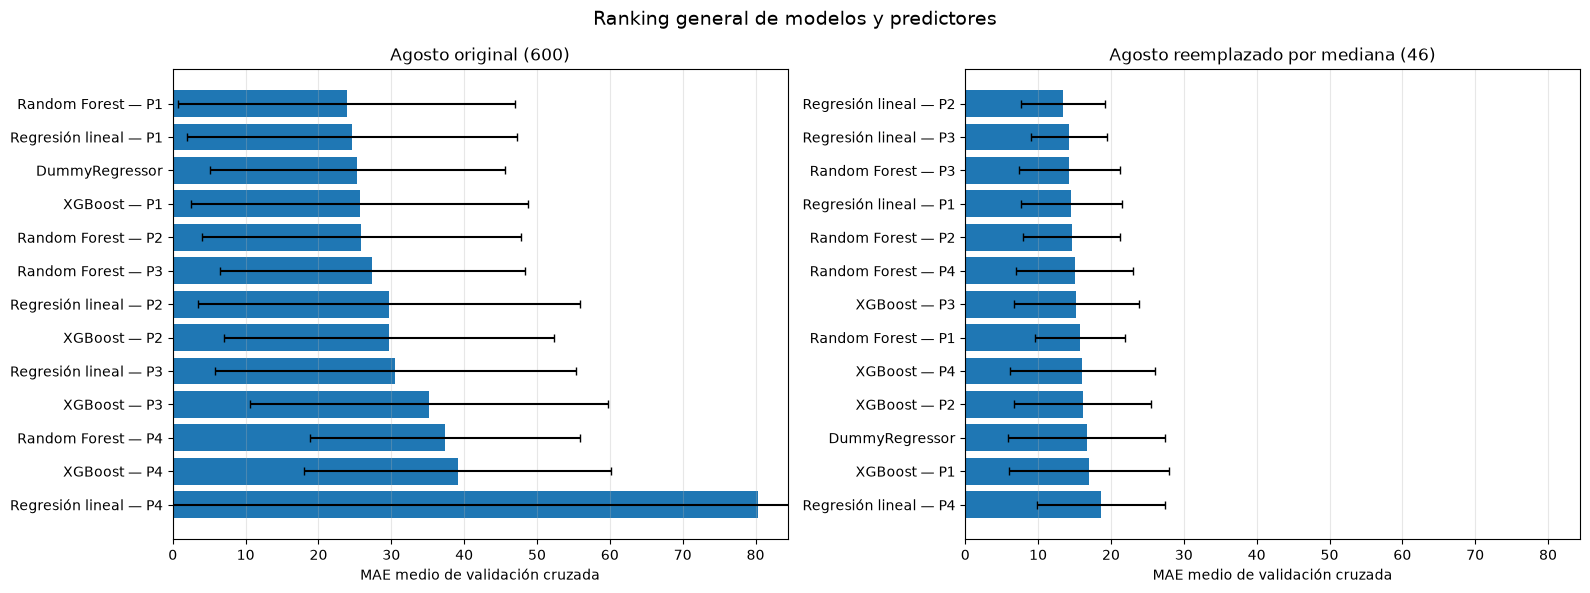

In [23]:
# ============================================================
# RANKING GENERAL DE MODELOS POR MAE
# ============================================================

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))

escenarios = [
    "Agosto original (600)",
    "Agosto reemplazado por mediana (46)"
]

# Límite común para comparar ambos escenarios
limite_x = (
    tabla_ranking_general_cv["MAE_CV"].max() * 1.05
)

for ax, escenario in zip(ejes, escenarios):

    tabla = tabla_ranking_general_cv.loc[
        tabla_ranking_general_cv["Escenario"] == escenario
    ].sort_values("MAE_CV", ascending=True)

    etiquetas = [
        f"{fila.Modelo} — {fila.Predictor}"
        if fila.Predictor != "—"
        else fila.Modelo
        for fila in tabla.itertuples()
    ]

    ax.barh(
        etiquetas,
        tabla["MAE_CV"],
        xerr=tabla["MAE_CV_std"],
        capsize=3
    )

    ax.set_title(escenario)
    ax.set_xlabel("MAE medio de validación cruzada")
    ax.set_ylabel("")
    ax.set_xlim(0, limite_x)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)

fig.suptitle(
    "Ranking general de modelos y predictores",
    fontsize=14
)

plt.tight_layout()
plt.show()

Cómo leerlo:
- Cada barra representa una combinación de modelo y predictor evaluada en el escenario correspondiente.
- Una barra más corta indica un MAE medio menor y, por tanto, mejor rendimiento según nuestra métrica principal.
- Las líneas horizontales muestran la desviación estándar del MAE entre los pliegues. Si son grandes, el rendimiento varía bastante según el período evaluado.

#### 11.2 Mejores modelos por familia y escenario


In [24]:

# ============================================================
# 11.2 MEJORES MODELOS POR FAMILIA Y ESCENARIO
# ============================================================

ranking_cv = comparacion_final_cv.copy()

# Identificar predictor
ranking_cv["Predictor"] = (
    ranking_cv["Modelo"]
    .str.extract(r"(Predictor \d+)", expand=False)
    .str.replace("Predictor ", "P", regex=False)
    .fillna("—")
)

# Identificar familia
ranking_cv["Familia"] = "DummyRegressor"

ranking_cv.loc[
    ranking_cv["Modelo"].str.contains(
        "Regresión lineal", case=False
    ),
    "Familia"
] = "Regresión lineal"

ranking_cv.loc[
    ranking_cv["Modelo"].str.contains(
        "Random Forest", case=False
    ),
    "Familia"
] = "Random Forest"

ranking_cv.loc[
    ranking_cv["Modelo"].str.contains(
        "XGBoost", case=False
    ),
    "Familia"
] = "XGBoost"

# Seleccionar el mejor modelo de cada familia y escenario
indices_mejores = (
    ranking_cv
    .sort_values(["MAE_CV", "RMSE_CV"])
    .groupby(["Escenario", "Familia"], sort=False)
    .head(1)
    .index
)

tabla_mejores_modelos_cv = (
    ranking_cv.loc[indices_mejores]
    .copy()
)

# Cambiar las etiquetas para facilitar la lectura
tabla_mejores_modelos_cv["Escenario"] = (
    tabla_mejores_modelos_cv["Escenario"].replace({
        "Agosto original": "Agosto original (600)",
        "Agosto reemplazado por mediana":
            "Agosto reemplazado por mediana (46)"
    })
)

# Ordenar primero por escenario y luego por menor MAE
orden_escenarios = {
    "Agosto original (600)": 1,
    "Agosto reemplazado por mediana (46)": 2
}

tabla_mejores_modelos_cv["orden_escenario"] = (
    tabla_mejores_modelos_cv["Escenario"].map(orden_escenarios)
)

tabla_mejores_modelos_cv = (
    tabla_mejores_modelos_cv
    .sort_values(["orden_escenario", "MAE_CV", "RMSE_CV"])
    .reset_index(drop=True)
)

columnas_resultados = [
    "Escenario", "Familia", "Predictor",
    "MAE_CV", "MAE_CV_std",
    "RMSE_CV", "RMSE_CV_std"
]

display(
    tabla_mejores_modelos_cv[columnas_resultados]
    .round(3)
    .style.hide(axis="index").format(precision=3)
)

Escenario,Familia,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
Agosto original (600),Random Forest,P1,23.900,23.141,47.597,66.070
Agosto original (600),Regresión lineal,P1,24.647,22.630,48.583,65.308
Agosto original (600),DummyRegressor,—,25.352,20.197,49.198,58.093
Agosto original (600),XGBoost,P1,25.654,23.099,50.720,64.673
Agosto reemplazado por mediana (46),Regresión lineal,P2,13.412,5.734,18.975,11.186
Agosto reemplazado por mediana (46),Random Forest,P3,14.264,6.933,20.004,11.977
Agosto reemplazado por mediana (46),XGBoost,P3,15.259,8.593,20.723,13.214
Agosto reemplazado por mediana (46),DummyRegressor,—,16.678,10.789,21.319,13.889


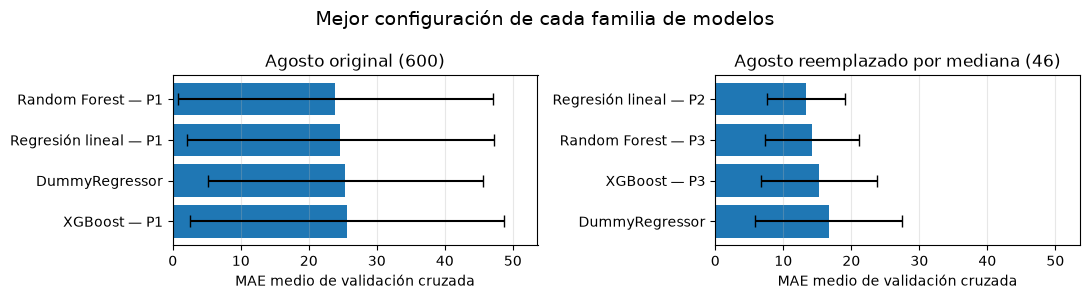

In [25]:
# ============================================================
# COMPARACIÓN VISUAL DE LOS MEJORES MODELOS
# ============================================================

fig, ejes = plt.subplots(1, 2, figsize=(11, 3))

escenarios = [
    "Agosto original (600)",
    "Agosto reemplazado por mediana (46)"
]

# Usar el mismo límite del eje X en ambos gráficos
limite_x = (
    tabla_mejores_modelos_cv["MAE_CV"]
    + tabla_mejores_modelos_cv["MAE_CV_std"]
).max() * 1.10

for ax, escenario in zip(ejes, escenarios):

    tabla = tabla_mejores_modelos_cv.loc[
        tabla_mejores_modelos_cv["Escenario"] == escenario
    ].sort_values("MAE_CV", ascending=True)

    etiquetas = [
        f"{fila.Familia} — {fila.Predictor}"
        if fila.Predictor != "—"
        else fila.Familia
        for fila in tabla.itertuples()
    ]

    ax.barh(
        etiquetas,
        tabla["MAE_CV"],
        xerr=tabla["MAE_CV_std"],
        capsize=4
    )

    ax.set_title(escenario)
    ax.set_xlabel("MAE medio de validación cruzada")
    ax.set_ylabel("")
    ax.set_xlim(0, limite_x)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)

fig.suptitle(
    "Mejor configuración de cada familia de modelos",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### 11.3 Los 5 mejores modelos del ranking general


In [26]:
# ============================================================
# 11.3 LOS 5 MEJORES MODELOS DEL RANKING GENERAL
# ============================================================

mejores_cinco = (
    tabla_ranking_general_cv
    .sort_values(["MAE_CV", "RMSE_CV"])
    .head(5)
    .reset_index(drop=True)
    .copy()
)

# Recalcular el puesto dentro de los cinco seleccionados
mejores_cinco["Puesto"] = range(1, len(mejores_cinco) + 1)

columnas_mejores = [
    "Puesto", "Modelo", "Predictor", "Escenario",
    "MAE_CV", "MAE_CV_std", "RMSE_CV", "RMSE_CV_std"
]


display(
    mejores_cinco[columnas_mejores]
    .round(3)
    .style.hide(axis="index").format(precision=3)
)

Puesto,Modelo,Predictor,Escenario,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
1,Regresión lineal,P2,Agosto reemplazado por mediana (46),13.412,5.734,18.975,11.186
2,Regresión lineal,P3,Agosto reemplazado por mediana (46),14.244,5.215,21.087,12.374
3,Random Forest,P3,Agosto reemplazado por mediana (46),14.264,6.933,20.004,11.977
4,Regresión lineal,P1,Agosto reemplazado por mediana (46),14.579,6.916,19.856,12.240
5,Random Forest,P2,Agosto reemplazado por mediana (46),14.601,6.704,20.172,11.779


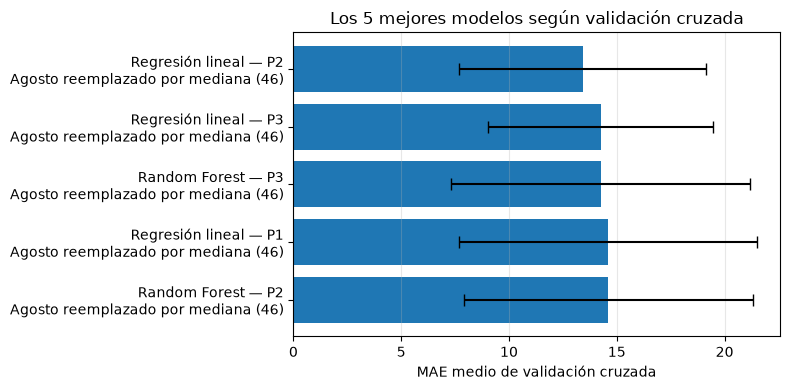

In [27]:
# ============================================================
# GRÁFICO DE LOS 5 MEJORES MODELOS
# ============================================================

tabla_grafico = mejores_cinco.sort_values(
    "MAE_CV",
    ascending=True
).copy()

etiquetas = []

for fila in tabla_grafico.itertuples():

    if fila.Predictor != "—":
        etiqueta = f"{fila.Modelo} — {fila.Predictor}"
    else:
        etiqueta = fila.Modelo

    etiqueta += f"\n{fila.Escenario}"
    etiquetas.append(etiqueta)

fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(
    etiquetas,
    tabla_grafico["MAE_CV"],
    xerr=tabla_grafico["MAE_CV_std"],
    capsize=4
)

ax.set_title("Los 5 mejores modelos según validación cruzada")
ax.set_xlabel("MAE medio de validación cruzada")
ax.set_ylabel("")
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### 12. Comparación del error entre pliegues: regresión lineal P2 vs. P3


In [28]:

# ============================================================
# 12. COMPARACIÓN DE ESTABILIDAD: REGRESIÓN LINEAL P2 VS. P3
# ============================================================

resultados_pliegues = []

# Comparar P2 y P3 en el escenario con agosto reemplazado
predictores_comparar = ["Predictor 2", "Predictor 3"]

for nombre in predictores_comparar:

    datos = datos_modelosA[nombre]

    X_train = datos["X_train"].reset_index(drop=True)
    y_train = datos["y_train"].reset_index(drop=True)

    # Evaluar los mismos cinco pliegues temporales
    for numero_pliegue, (idx_train, idx_val) in enumerate(
        cv_temporal.split(X_train), start=1
    ):

        modelo = Pipeline([
            ("escalador", StandardScaler()),
            ("regresion", LinearRegression())
        ])

        modelo.fit(
            X_train.iloc[idx_train],
            y_train.iloc[idx_train]
        )

        predicciones = modelo.predict(X_train.iloc[idx_val])
        valores_reales = y_train.iloc[idx_val]

        resultados_pliegues.append({
            "Predictor": nombre.replace("Predictor ", "P"),
            "Pliegue": numero_pliegue,
            "MAE": mean_absolute_error(
                valores_reales, predicciones
            ),
            "RMSE": np.sqrt(
                mean_squared_error(valores_reales, predicciones)
            )
        })


# Crear tabla de resultados
tabla_pliegues = pd.DataFrame(resultados_pliegues)

tabla_comparacion_pliegues = tabla_pliegues.pivot(
    index="Pliegue",
    columns="Predictor",
    values=["MAE", "RMSE"]
)

# Simplificar los nombres de las columnas
tabla_comparacion_pliegues.columns = [
    f"{metrica}_{predictor}"
    for metrica, predictor in tabla_comparacion_pliegues.columns
]

tabla_comparacion_pliegues = tabla_comparacion_pliegues.reset_index()

# Diferencia negativa: P2 tiene menor error
tabla_comparacion_pliegues["Diferencia_MAE_P2_menos_P3"] = (
    tabla_comparacion_pliegues["MAE_P2"]
    - tabla_comparacion_pliegues["MAE_P3"]
)

tabla_comparacion_pliegues["Diferencia_RMSE_P2_menos_P3"] = (
    tabla_comparacion_pliegues["RMSE_P2"]
    - tabla_comparacion_pliegues["RMSE_P3"]
)

print("COMPARACIÓN POR PLIEGUE TEMPORAL")
display(tabla_comparacion_pliegues.style.hide(axis="index").format(precision=3))

# Resumir cuántos pliegues gana cada predictor
print("\nCANTIDAD DE PLIEGUES CON MENOR ERROR")

print(
    "P2 gana en MAE:",
    (tabla_comparacion_pliegues["Diferencia_MAE_P2_menos_P3"] < 0).sum(),
    "de 5 pliegues"
)

print(
    "P2 gana en RMSE:",
    (tabla_comparacion_pliegues["Diferencia_RMSE_P2_menos_P3"] < 0).sum(),
    "de 5 pliegues"
)


COMPARACIÓN POR PLIEGUE TEMPORAL


Pliegue,MAE_P2,MAE_P3,RMSE_P2,RMSE_P3,Diferencia_MAE_P2_menos_P3,Diferencia_RMSE_P2_menos_P3
1,16.742,16.834,24.600,24.474,-0.092,0.126
2,21.134,21.229,35.511,41.165,-0.095,-5.654
3,6.073,7.163,7.035,10.260,-1.089,-3.225
4,11.388,12.891,13.336,14.123,-1.503,-0.788
5,11.723,13.103,14.390,15.414,-1.380,-1.024



CANTIDAD DE PLIEGUES CON MENOR ERROR
P2 gana en MAE: 5 de 5 pliegues
P2 gana en RMSE: 4 de 5 pliegues


### 13. Evaluación final en el conjunto de prueba
REGRESIÓN LINEAL + P2 — AGOSTO REEMPLAZADO POR MEDIANA

In [29]:
# ============================================================
# 13. EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA
# REGRESIÓN LINEAL + P2 — AGOSTO REEMPLAZADO POR MEDIANA
# ============================================================

# Recuperar los datos de prueba del predictor seleccionado
datos_finales = datos_modelosA["Predictor 2"]

X_train = datos_finales["X_train"]
y_train = datos_finales["y_train"]

X_test = datos_finales["X_test"]
y_test = datos_finales["y_test"]

# Entrenar el modelo con todos los meses de entrenamiento
modelo_final = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

modelo_final.fit(X_train, y_train)

# Predecir los 12 meses reservados
predicciones_test = modelo_final.predict(X_test)

# Calcular métricas finales
mae_test = mean_absolute_error(y_test, predicciones_test)

rmse_test = np.sqrt(
    mean_squared_error(y_test, predicciones_test)
)

resultados_test_final = pd.DataFrame({
    "Modelo": ["Regresión lineal"],
    "Predictor": ["P2"],
    "Escenario": ["Agosto reemplazado por mediana"],
    "MAE_test": [mae_test],
    "RMSE_test": [rmse_test]
})

print("RESULTADOS FINALES EN LOS 12 MESES DE PRUEBA")
display(resultados_test_final.style.hide(axis="index").format(precision=3))

# Tabla con valores observados y predichos
comparacion_test_final = pd.DataFrame({
    "Año": datos_finales["prueba"]["event_year"].to_numpy(),
    "Mes": datos_finales["prueba"]["event_month"].to_numpy(),
    "Sismos_reales": y_test.to_numpy(),
    "Sismos_predichos": predicciones_test
})

comparacion_test_final["Sismos_predichos"] = (
    comparacion_test_final["Sismos_predichos"].round(2)
)

display(comparacion_test_final.style.hide(axis="index").format(precision=3))

RESULTADOS FINALES EN LOS 12 MESES DE PRUEBA


Modelo,Predictor,Escenario,MAE_test,RMSE_test
Regresión lineal,P2,Agosto reemplazado por mediana,8.589,10.094


Año,Mes,Sismos_reales,Sismos_predichos
2025,9,49,50.110
2025,10,69,48.380
2025,11,52,55.950
2025,12,54,53.750
2026,1,44,54.900
2026,2,37,49.150
2026,3,36,45.650
2026,4,31,42.350
2026,5,51,39.550
2026,6,39,44.570


#### 13.1 Comparar el modelo final con el Dummy regressor


In [30]:
# ============================================================
# 13.1 COMPARAR EL MODELO FINAL CON EL DUMMY REGRESSOR
# ============================================================

# Recuperar las métricas del Dummy en el mismo escenario
resultado_dummy = test_base.loc[
    (test_base["Escenario"] == "Agosto reemplazado por mediana")
    & (test_base["Predictor"] == "Predictor 2")
].iloc[0]

comparacion_baseline = pd.DataFrame({
    "Modelo": ["DummyRegressor", "Regresión lineal"],
    "Predictor": ["No utiliza predictores", "P2"],
    "MAE_test": [
        resultado_dummy["MAE_test"],
        mae_test
    ],
    "RMSE_test": [
        resultado_dummy["RMSE_test"],
        rmse_test
    ]
})

# Calcular cuánto reduce el error la regresión lineal
reduccion_mae = (
    (resultado_dummy["MAE_test"] - mae_test)
    / resultado_dummy["MAE_test"] * 100
)

reduccion_rmse = (
    (resultado_dummy["RMSE_test"] - rmse_test)
    / resultado_dummy["RMSE_test"] * 100
)

print("COMPARACIÓN SOBRE LOS MISMOS 12 MESES")
display(comparacion_baseline.style.hide(axis="index").format(precision=3))

print(f"Reducción del MAE: {reduccion_mae:.1f}%")
print(f"Reducción del RMSE: {reduccion_rmse:.1f}%")

COMPARACIÓN SOBRE LOS MISMOS 12 MESES


Modelo,Predictor,MAE_test,RMSE_test
DummyRegressor,No utiliza predictores,8.356,10.544
Regresión lineal,P2,8.589,10.094


Reducción del MAE: -2.8%
Reducción del RMSE: 4.3%


La Regresión Lineal con el conjunto de predictores P2 fue seleccionada como la mejor candidata según la validación cruzada, con un MAE de 13,412 y un RMSE de 18,975, mejorando ambas métricas respecto del DummyRegressor. Sin embargo, en el conjunto de prueba de 12 meses, los resultados fueron mixtos: el Dummy obtuvo un MAE ligeramente menor (8,356 frente a 8,589), mientras que la regresión logró un RMSE inferior (10,094 frente a 10,544). Por lo tanto, no se encontró una superioridad consistente de la regresión frente a la referencia estadística.

Aunque LR no mostró una mejora consistente frente al DummyRegressor en el conjunto de prueba, se implementó una consulta que permite estimar la cantidad de sismos para los próximos meses. El objetivo es observar cómo se comporta el modelo al ampliar el horizonte de estimación, sin asumir que sus resultados serán necesariamente más precisos que los de la referencia estadística.

### Consulta del usuario

*¿Cuántos sismos se esperan en Argentina durante los próximos X meses?*

**Entrada**: cantidad de meses para los que se solicita la estimación, entre 1 y 12.

**Salida**: cantidad total estimada de sismos para el período solicitado, acompañada de una aclaración sobre el alcance de la estimación.

La estimación se basa en el análisis estadístico de los registros históricos de actividad sísmica de Argentina entre octubre de 2016 y agosto de 2026. No constituye una predicción determinista de eventos individuales.

### 14. Implementación de la consulta

#### 14.1 Preparar el modelo final


In [31]:

# ============================================================
# 14.1. PREPARAR EL MODELO FINAL
# ============================================================

columnas_P2 = [
    "sismos_mes_anterior",
    "sismos_ultimos_3_meses",
    "sismos_ultimos_6_meses"
]

# Datos del escenario que reemplaza agosto de 2021 por la mediana
P2_datos_final = predictores_limpiosA["Predictor 2"].copy()

X_final = P2_datos_final[columnas_P2]
y_final = P2_datos_final["cantidad_sismos"]

# Crear y ajustar el modelo operativo
modelo_request = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

modelo_request.fit(X_final, y_final)

# Historial de cantidades mensuales conocidas
historial_sismos = y_final.astype(float).tolist()

print("Modelo preparado.")
print("Meses utilizados:", len(P2_datos_final))
print("Últimos registros del historial:")

display(
    P2_datos_final[
        ["event_year", "event_month", "cantidad_sismos"]
        + columnas_P2
    ].tail(6).style.hide(axis="index").format(precision=1)
)


Modelo preparado.
Meses utilizados: 113
Últimos registros del historial:


event_year,event_month,cantidad_sismos,sismos_mes_anterior,sismos_ultimos_3_meses,sismos_ultimos_6_meses
2026,3,36,37.0,135.0,305.0
2026,4,31,36.0,117.0,292.0
2026,5,51,31.0,104.0,254.0
2026,6,39,51.0,118.0,253.0
2026,7,51,39.0,121.0,238.0
2026,8,40,51.0,141.0,245.0


#### 14.2 Consulta de estimación de actividad sísmica


In [32]:

# ============================================================
# 14.2. CONSULTA DE ESTIMACIÓN DE ACTIVIDAD SÍSMICA
# ============================================================

def consultar_sismos():

    # Solicitar la duración del período de referencia
    while True:
        entrada = input(
            "¿Para cuántos meses querés estimar la cantidad de sismos? (1 a 12): "
        )

        try:
            meses = int(entrada)

            if 1 <= meses <= 12:
                break

            print("Ingresá un número entero entre 1 y 12.")

        except ValueError:
            print("Entrada inválida. Ingresá un número entero.")

    # Copiar el historial sin modificar los datos originales
    historial = historial_sismos.copy()

    total_estimado = 0

    # Estimar la cantidad de sismos para cada mes del período
    for paso in range(meses):

        X_futuro = pd.DataFrame([{
            "sismos_mes_anterior": historial[-1],
            "sismos_ultimos_3_meses": sum(historial[-3:]),
            "sismos_ultimos_6_meses": sum(historial[-6:])
        }])

        prediccion = modelo_request.predict(X_futuro)[0]

        # Evitar cantidades negativas y redondear a enteros
        prediccion = max(0, int(np.floor(prediccion + 0.5)))

        # Acumular la estimación del período
        total_estimado += prediccion

        # Incorporar la estimación al historial para el siguiente paso
        historial.append(prediccion)

    # Mostrar el resultado agregado
    print("\nEstimación de actividad sísmica")
    print(f"Período de referencia: {meses} {'mes' if meses == 1 else 'meses'}")
    print(f"Cantidad total estimada: {total_estimado} sismos")
    print(
        "Estimación basada en los patrones históricos "
        "de actividad sísmica de Argentina entre octubre de 2016 y agosto de 2026."
    )

    return total_estimado


In [33]:

resultado_consulta = consultar_sismos()



Estimación de actividad sísmica
Período de referencia: 3 meses
Cantidad total estimada: 138 sismos
Estimación basada en los patrones históricos de actividad sísmica de Argentina entre octubre de 2016 y agosto de 2026.


### 15. Comparación operativa

En esta sección se analiza cómo evolucionan las estimaciones al ampliar el horizonte de predicción.

En la retroalimentación recursiva, cada predicción se incorpora al historial para calcular la del mes siguiente. Esto permite observar si las estimaciones tienden a estabilizarse y cómo cambia la secuencia a medida que aumenta el horizonte.

Además, se compara esta estrategia con una variante ponderada que combina la predicción del modelo con el promedio de los últimos tres meses, utilizando una ponderación del 50 % para cada componente.
La comparación permite observar las diferencias entre ambas secuencias de estimaciones y sus acumulados a lo largo del horizonte considerado.

In [34]:

# --------------------------------------------------------
# ACTIVIDAD SÍSMICA DE LOS ÚLTIMOS 3 Y 6 MESES


ultimos_3_meses = historial_sismos[-3:]
ultimos_6_meses = historial_sismos[-6:]

total_3_meses = sum(ultimos_3_meses)
total_6_meses = sum(ultimos_6_meses)

promedio_3_meses = total_3_meses / 3
promedio_6_meses = total_6_meses / 6

print("Actividad sísmica reciente")
print("\nÚltimos 3 meses:")
print(f"Cantidad total de sismos: {total_3_meses:.0f}")
print(f"Promedio mensual: {promedio_3_meses:.2f}")

print("\nÚltimos 6 meses:")
print(f"Cantidad total de sismos: {total_6_meses:.0f}")
print(f"Promedio mensual: {promedio_6_meses:.2f}")


Actividad sísmica reciente

Últimos 3 meses:
Cantidad total de sismos: 130
Promedio mensual: 43.33

Últimos 6 meses:
Cantidad total de sismos: 248
Promedio mensual: 41.33


#### 15.1 Retroalimentación Original vs. Ponderada

Mes proyectado,Predicción original,Predicción ponderada,Diferencia (ponderada - original)
1,45,44,-1
2,47,46,-1
3,46,45,-1
4,47,46,-1
5,48,46,-2
6,48,46,-2
7,48,47,-1
8,49,47,-2
9,49,47,-2
10,49,47,-2


Historial utilizado: 113 meses
Horizonte proyectado: 12 meses
Total estimado original: 574
Total estimado ponderado: 555
Promedio mensual del período de evaluación final: 46.08
Total de sismos observados en el período de evaluación final: 553


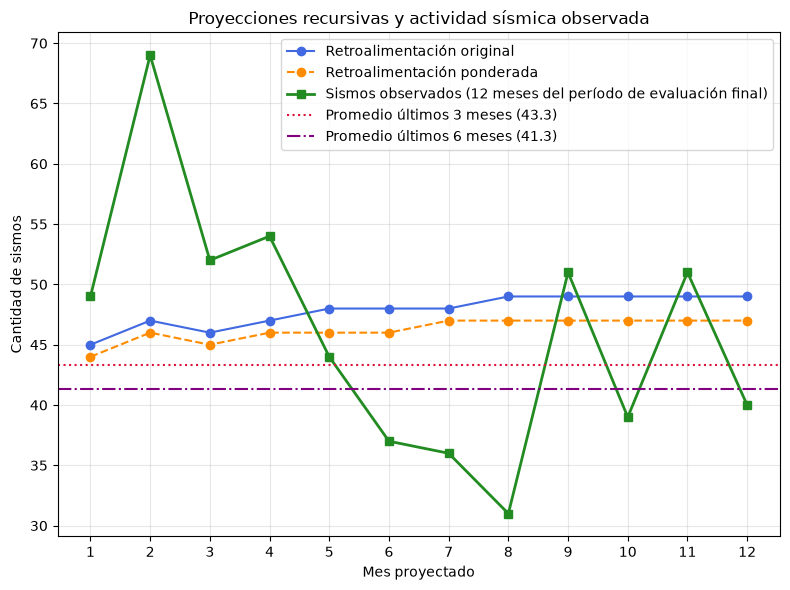

In [35]:

# ============================================================
# 15.1 COMPARACIÓN OPERATIVA:
# RETROALIMENTACIÓN ORIGINAL VS. PONDERADA
# ============================================================

# Ambas variantes utilizan modelo_request, entrenado con los
# 113 meses, y parten del mismo historial_sismos.
# No modifica la función consultar_sismos() ni sus variables.

horizonte = 12
peso_modelo = 0.50
peso_historial = 0.50

predicciones_originales_113 = []
predicciones_ponderadas_113 = []

historial_original = historial_sismos.copy()
historial_ponderado = historial_sismos.copy()

for _ in range(horizonte):

    # --------------------------------------------------------
    # 1. Predicción recursiva original
    # --------------------------------------------------------

    X_original = pd.DataFrame([{
        "sismos_mes_anterior": historial_original[-1],
        "sismos_ultimos_3_meses": sum(historial_original[-3:]),
        "sismos_ultimos_6_meses": sum(historial_original[-6:])
    }], columns=columnas_P2)

    pred_original = modelo_request.predict(X_original)[0]
    pred_original = max(0, int(np.floor(pred_original + 0.5)))

    predicciones_originales_113.append(pred_original)
    historial_original.append(pred_original)

    # --------------------------------------------------------
    # 2. Predicción recursiva ponderada
    # --------------------------------------------------------

    X_ponderado = pd.DataFrame([{
        "sismos_mes_anterior": historial_ponderado[-1],
        "sismos_ultimos_3_meses": sum(historial_ponderado[-3:]),
        "sismos_ultimos_6_meses": sum(historial_ponderado[-6:])
    }], columns=columnas_P2)

    pred_modelo = modelo_request.predict(X_ponderado)[0]
    promedio_reciente = np.mean(historial_ponderado[-3:])

    pred_ponderada = (
        peso_modelo * pred_modelo
        + peso_historial * promedio_reciente
    )

    pred_ponderada = max(
        0, int(np.floor(pred_ponderada + 0.5))
    )

    predicciones_ponderadas_113.append(pred_ponderada)
    historial_ponderado.append(pred_ponderada)


# ------------------------------------------------------------
# 3. Comparación de las proyecciones
# ------------------------------------------------------------

comparacion_operativa_113 = pd.DataFrame({
    "Mes proyectado": range(1, horizonte + 1),
    "Predicción original": predicciones_originales_113,
    "Predicción ponderada": predicciones_ponderadas_113
})

comparacion_operativa_113["Diferencia (ponderada - original)"] = (
    comparacion_operativa_113["Predicción ponderada"]
    - comparacion_operativa_113["Predicción original"]
)

display(comparacion_operativa_113.style.hide(axis="index"))

print(f"Historial utilizado: {len(historial_sismos)} meses")
print(f"Horizonte proyectado: {horizonte} meses")
print(f"Total estimado original: {sum(predicciones_originales_113)}")
print(f"Total estimado ponderado: {sum(predicciones_ponderadas_113)}")






# ------------------------------------------------------------
# 4. Gráfico comparativo con contexto histórico
# ------------------------------------------------------------

# Recuperar los 12 meses reales del período de test
datos_historicos = P2_datos_final.reset_index(drop=True).copy()
datos_test_referencia = datos_historicos.tail(12).copy()

sismos_reales_test = datos_test_referencia[
    "cantidad_sismos"
].to_numpy(dtype=float)

# Resumen de la actividad sísmica observada
print(
    "Promedio mensual del período de evaluación final:",
    f"{sismos_reales_test.mean():.2f}"
)

print(
    "Total de sismos observados en el período de evaluación final:",
    f"{sismos_reales_test.sum():.0f}"
)

plt.figure(figsize=(8, 6))

meses = comparacion_operativa_113["Mes proyectado"]

plt.plot(
    meses,
    comparacion_operativa_113["Predicción original"],
    color="royalblue",
    marker="o",
    label="Retroalimentación original"
)

plt.plot(
    meses,
    comparacion_operativa_113["Predicción ponderada"],
    color="darkorange",
    marker="o",
    linestyle="--",
    label="Retroalimentación ponderada"
)

plt.plot(
    meses,
    sismos_reales_test,
    color="forestgreen",
    marker="s",
    linewidth=2,
    label="Sismos observados (12 meses del período de evaluación final)"
)

plt.axhline(
    promedio_3_meses,
    color="crimson",
    linestyle=":",
    label=f"Promedio últimos 3 meses ({promedio_3_meses:.1f})"
)

plt.axhline(
    promedio_6_meses,
    color="purple",
    linestyle="-.",
    label=f"Promedio últimos 6 meses ({promedio_6_meses:.1f})"
)

plt.xticks(range(1, horizonte + 1))
plt.xlabel("Mes proyectado")
plt.ylabel("Cantidad de sismos")
plt.title("Proyecciones recursivas y actividad sísmica observada")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


#### 15.2 Tabla final: sismos acumulados por horizonte


In [36]:

# ============================================================
# 15.2 TABLA FINAL: SISMOS ACUMULADOS POR HORIZONTE
# ============================================================

# 1. Acumulados de las proyecciones operativas
meses = np.arange(1, horizonte + 1)

acumulado_original = np.cumsum(predicciones_originales_113)
acumulado_ponderado = np.cumsum(predicciones_ponderadas_113)

# 2. Referencias basadas en los promedios históricos recientes
acumulado_promedio_3m = promedio_3_meses * meses
acumulado_promedio_6m = promedio_6_meses * meses

# 3. Referencia Dummy: media mensual de los 113 meses históricos
promedio_dummy_113 = np.mean(historial_sismos)
acumulado_dummy = promedio_dummy_113 * meses

# 4. Recuperar el período histórico de test (últimos 12 meses)
datos_historicos = P2_datos_final.reset_index(drop=True).copy()
datos_test_referencia = datos_historicos.tail(12).copy()

sismos_reales_test = datos_test_referencia[
    "cantidad_sismos"
].to_numpy(dtype=float)

acumulado_real_test = np.cumsum(sismos_reales_test)

# 5. Tabla comparativa
comparacion_acumulada = pd.DataFrame({
    "Meses proyectados": meses,
    "Regresión original": acumulado_original,
    "Regresión ponderada": acumulado_ponderado,
    "Dummy: media de 113 meses": acumulado_dummy,
    "Referencia: prom. de 3 meses": acumulado_promedio_3m,
    "Referencia: prom. de 6 meses": acumulado_promedio_6m,
    "Acumulado del periodo del test": acumulado_real_test
})

display(comparacion_acumulada.style.hide(axis="index").format(precision=1))



Meses proyectados,Regresión original,Regresión ponderada,Dummy: media de 113 meses,Referencia: prom. de 3 meses,Referencia: prom. de 6 meses,Acumulado del periodo del test
1,45,44,49.3,43.3,41.3,49.0
2,92,90,98.5,86.7,82.7,118.0
3,138,135,147.8,130.0,124.0,170.0
4,185,181,197.0,173.3,165.3,224.0
5,233,227,246.3,216.7,206.7,268.0
6,281,273,295.5,260.0,248.0,305.0
7,329,320,344.8,303.3,289.3,341.0
8,378,367,394.1,346.7,330.7,372.0
9,427,414,443.3,390.0,372.0,423.0
10,476,461,492.6,433.3,413.3,462.0


### 16. Conclusiones

En este escenario, la regresión lineal (LR) obtuvo resultados más cercanos al acumulado real en comparación con el Dummy y los promedios de los últimos 3 y 6 meses, extrapolados a un año. Las diferencias entre estas estimaciones reflejan la variabilidad de la actividad sísmica: los promedios generales pueden ocultar períodos con cantidades de sismos muy inferiores o superiores a las observadas durante el año del periodo de evaluación(test).

Por eso, aunque LR se acercó más al total real en este caso, la comparación corresponde a un único período histórico de 12 meses. Otro año podría presentar una actividad sísmica diferente y modificar los resultados, por lo que esta cercanía no garantiza un mejor desempeño en otros períodos.

En términos generales, los experimentos realizados muestran que la capacidad predictiva depende de las variables utilizadas, el horizonte de predicción y el método elegido. Si bien algunos modelos lograron resultados cercanos a las referencias estadísticas en determinados escenarios, no se encontró una mejora predictiva suficientemente consistente como para afirmar que un método sea superior en general. Esto resalta la dificultad de predecir la actividad sísmica únicamente a partir de sus registros históricos y la importancia de interpretar las proyecciones considerando la variabilidad de los datos y las limitaciones del análisis.

Como análisis complementario, se desarrolló una notebook alternativa en la que se plantearon distintos horizontes de predicción como variables objetivo desde el inicio, en lugar de generar las estimaciones mediante retroalimentación recursiva. Se evaluaron los mismos predictores y modelos para comprobar si este enfoque mejoraba los resultados. Sin embargo, las pruebas tampoco mostraron una mejora suficientemente consistente frente al Dummy, que mantuvo un desempeño competitivo. Por lo tanto, cambiar la estrategia de construcción de los objetivos no permitió obtener una ventaja predictiva clara y se conservó la conclusión general sobre las limitaciones de los modelos evaluados.